# Student Performance: Data Preprocessing, Statistical Analysis and Visualization
**Endterm — Data Analysis and Visualization · VibeCoding_Expert**  
NGO LAM TIEN (524H0195), NGUYEN CONG THANH (524H0191), NGUYEN LE NHAT TAM (524H0186), NGO BINH MINH (524H0169)  
Advisor: Ho Thi Linh, Ph.D. · Report date: 20 October 2026

This notebook follows assignment Parts I–IV. Every figure and reported statistic comes from this execution. The questions are: how do grades vary; how does missing-value treatment change the data; which original factors have the strongest observed association with G3; and what do group comparisons add?

**Data choice:** UCI Student Performance, Portuguese-language subject only. It contains school records and questionnaire responses from two Portuguese schools, not TDTU students. The original dataset is complete. Artificial missingness is a separate teaching experiment; Parts II–IV use the validated original measurements. No predictive model or causal effect is claimed.

After installing the pinned dependencies, run all cells offline. Paths are relative to this project; the executed notebook also serves as the presentation fallback.

In [1]:
from pathlib import Path
import hashlib
import json
import re
import sys
import importlib.metadata
import numpy as np
import pandas as pd
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
from matplotlib.cbook import boxplot_stats
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd().resolve()

# Find the dataset in current folder or standard subfolders
candidates = [
    Path('student-por.csv'),
    ROOT / 'student-por.csv',
    ROOT / 'data/raw/student-por.csv',
    ROOT.parent / 'data/raw/student-por.csv',
]
raw_path = next((p for p in candidates if p.exists()), None)
assert raw_path is not None, 'student-por.csv not found in current folder or data/raw/'

# Domain definitions embedded directly (no external module dependency)
BANDS = ['0–9', '10–14', '15–20']
RAW_COLUMNS = 'school sex age address famsize Pstatus Medu Fedu Mjob Fjob reason guardian traveltime studytime failures schoolsup famsup paid activities nursery higher internet romantic famrel freetime goout Dalc Walc health absences G1 G2 G3'.split()
NUMERIC_COLUMNS = 'age Medu Fedu traveltime studytime failures famrel freetime goout Dalc Walc health absences G1 G2 G3'.split()

def performance_bands(grades):
    '''Analyst-defined bands, not an official grading policy.'''
    if grades.isna().any() or not grades.between(0, 20).all():
        raise ValueError('Grades must be complete and lie in [0, 20].')
    return pd.cut(grades, [-1, 9, 14, 20], labels=BANDS, ordered=True)

def normalize_within_group(frame, group='school', column='G3'):
    '''Relative group scale; a constant group is assigned zero.'''
    if frame[[group, column]].isna().any().any():
        raise ValueError('Group normalization requires complete group/value columns.')
    if not np.isfinite(frame[column]).all():
        raise ValueError('Normalization values must be finite.')
    grouped = frame.groupby(group, observed=True)[column]
    low = grouped.transform('min')
    span = grouped.transform('max') - low
    return (frame[column] - low).div(span.where(span.ne(0), 1))

def comprehensive_report(frame):
    '''Display and return a JSON-safe summary without reading files/global data.'''
    required = {'G1', 'G2', 'G3', 'performance_band'}
    if not required.issubset(frame.columns):
        raise ValueError(f'Missing required columns: {sorted(required - set(frame.columns))}')
    total = len(frame)
    counts = frame['performance_band'].value_counts().reindex(BANDS, fill_value=0)
    distribution = {
        band: {'count': int(count), 'percent': float(100 * count / total) if total else 0.0}
        for band, count in counts.items()
    }
    summary = {
        'total_records': total,
        'total_columns': len(frame.columns),
        'missing_by_column': {name: int(value) for name, value in frame.isna().sum().items()},
        'grade_statistics': json.loads(frame[['G1', 'G2', 'G3']].agg(['count', 'mean', 'std', 'min', 'median', 'max']).to_json()),
        'performance_distribution': distribution,
    }
    print(json.dumps(summary, ensure_ascii=False, indent=2, allow_nan=False))
    return summary

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 220)
sns.set_theme(style='whitegrid', palette='deep', font='DejaVu Sans', font_scale=1.05)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'axes.titleweight': 'bold'})
TABLES = ROOT / 'results/tables'
FIGURES = ROOT / 'results/figures'
PROCESSED = ROOT / 'data/processed'
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)

def save_table(frame, name, index=True):
    frame.to_csv(TABLES / f'{name}.csv', index=index)

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f'{name}.png', bbox_inches='tight', facecolor='white')
    fig.savefig(FIGURES / f'{name}.svg', bbox_inches='tight', facecolor='white')
    plt.show()

## PART I — Acquisition and preprocessing
### I.1 · Acquire and load the data
Source: [Cortez (2008), UCI Student Performance](https://doi.org/10.24432/C5TG7T), CC BY 4.0. The small original CSV is bundled for offline reproduction. Acquisition details and the original codebook are in `references/`.
CSV delimiter is a semicolon. The checksum guards against inadvertently switching subjects or modifying raw data. The original 33 columns include categorical, ordinal and quantitative fields. Integer storage does not make every field a continuous quantity: studytime is a four-level category, not a number of hours.

In [2]:
raw_hash = hashlib.sha256(raw_path.read_bytes()).hexdigest()
assert raw_hash == 'a7594a11d7771c0efe1a740824e0e833da9c4cad07c39a9766a874575563fb3f'
raw = pd.read_csv(raw_path, sep=';')
assert raw.shape == (649, 33)
assert raw.columns.tolist() == RAW_COLUMNS
assert raw.isnull().sum().sum() == 0
assert raw[NUMERIC_COLUMNS].apply(lambda s: pd.api.types.is_integer_dtype(s)).all()
assert raw[['G1', 'G2', 'G3']].apply(lambda s: s.between(0, 20).all()).all()
assert raw['studytime'].isin([1, 2, 3, 4]).all()
assert set(raw['school']) == {'GP', 'MS'}
assert raw['absences'].ge(0).all()
print('Verified original CSV:', raw.shape, 'SHA-256:', raw_hash)

Verified original CSV: (649, 33) SHA-256: a7594a11d7771c0efe1a740824e0e833da9c4cad07c39a9766a874575563fb3f


### I.2 · Explore the basic structure
Inspect both ends to detect parsing errors and inspect dtypes/info before transforming anything. Repeated attribute combinations are inspected, not automatically deleted: there is no reliable personal identifier in this anonymized dataset.

In [3]:
display(raw.head(5))
display(raw.tail(5))
print('shape =', raw.shape)
display(raw.dtypes.rename('dtype').to_frame())
raw.info()
print('Duplicate full attribute rows:', raw.duplicated().sum())
print('Observed grade ranges:')
display(raw[['G1', 'G2', 'G3', 'absences']].agg(['min', 'max']))
print('Recorded failures codes:', sorted(raw['failures'].unique()))
save_table(raw.dtypes.astype(str).rename('dtype').to_frame(), 'column_types')

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,0,yes,no,no,no,yes,yes,yes,no,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,no,yes,yes,yes,yes,yes,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,no,no,yes,yes,no,no,4,3,2,1,2,5,0,11,13,13


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
644,MS,F,19,R,GT3,T,2,3,services,other,course,mother,1,3,1,no,no,no,yes,no,yes,yes,no,5,4,2,1,2,5,4,10,11,10
645,MS,F,18,U,LE3,T,3,1,teacher,services,course,mother,1,2,0,no,yes,no,no,yes,yes,yes,no,4,3,4,1,1,1,4,15,15,16
646,MS,F,18,U,GT3,T,1,1,other,other,course,mother,2,2,0,no,no,no,yes,yes,yes,no,no,1,1,1,1,1,5,6,11,12,9
647,MS,M,17,U,LE3,T,3,1,services,services,course,mother,2,1,0,no,no,no,no,no,yes,yes,no,2,4,5,3,4,2,6,10,10,10
648,MS,M,18,R,LE3,T,3,2,services,other,course,mother,3,1,0,no,no,no,no,no,yes,yes,no,4,4,1,3,4,5,4,10,11,11


shape = (649, 33)


,dtype
school,object
sex,object
age,int64
address,object
famsize,object
Pstatus,object
Medu,int64
Fedu,int64
Mjob,object
Fjob,object


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    object
 20  higher    

,G1,G2,G3,absences
min,0,0,0,0
max,19,19,19,32


Recorded failures codes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


**Codebook cautions.** The theoretical grade scale is 0–20; not every value must appear in this subject. The supplied general absences range covers both subjects. The codebook's wording for failures is inconsistent at its upper category; the CSV's actual categories are retained and the upper code is not asserted to be an exact count. This issue is documented rather than silently repaired.

### I.3 · Simulate missingness and compare treatments
Use one numerical column, absences. `round(649 × 0.05) = 32`, so the actual masked fraction is approximately 4.93%. A seeded generator selects 32 distinct rows without replacement. This is an MCAR simulation by construction, not evidence that real missingness would be random. The original frame remains untouched.

In [4]:
rng = np.random.default_rng(42)
masked_indices = np.sort(rng.choice(raw.index.to_numpy(), size=round(0.05 * len(raw)), replace=False))
corrupted = raw.copy(deep=True)
corrupted['absences'] = corrupted['absences'].astype(float)
corrupted.loc[masked_indices, 'absences'] = np.nan
display(pd.DataFrame({'raw': raw.isnull().sum(), 'simulated': corrupted.isnull().sum()}))
print(f'Masked {len(masked_indices)}/{len(raw)} = {100 * len(masked_indices) / len(raw):.4f}%')
assert len(np.unique(masked_indices)) == 32
assert corrupted.isna().sum().sum() == 32
pd.testing.assert_frame_equal(corrupted.drop(columns='absences'), raw.drop(columns='absences'))
observed = ~corrupted['absences'].isna()
np.testing.assert_array_equal(corrupted.loc[observed, 'absences'], raw.loc[observed, 'absences'])

# Both treatments start from the same corrupted measurements.
observed_mean = corrupted['absences'].mean()
imputed = corrupted.copy(deep=True)
imputed['absences'] = imputed['absences'].fillna(observed_mean)
dropped = corrupted.dropna().copy()
treatments = {'Original': raw, 'Simulated missing': corrupted, 'Mean imputation': imputed, 'Drop missing': dropped}
missing_comparison = pd.DataFrame([
    {'variant': name, 'rows': len(frame), 'columns': frame.shape[1], 'missing_cells': int(frame.isna().sum().sum()),
     'absences_mean': frame['absences'].mean(), 'absences_std': frame['absences'].std(ddof=1)}
    for name, frame in treatments.items()
])
display(missing_comparison)
display(pd.DataFrame({'imputed': imputed.isnull().sum(), 'dropped': dropped.isnull().sum()}))
assert len(imputed) == 649 and len(dropped) == 617
assert imputed.isna().sum().sum() == dropped.isna().sum().sum() == 0
np.testing.assert_allclose(imputed.loc[masked_indices, 'absences'], observed_mean)
np.testing.assert_array_equal(imputed.loc[observed, 'absences'], raw.loc[observed, 'absences'])
pd.testing.assert_frame_equal(raw, pd.read_csv(raw_path, sep=';'))
save_table(missing_comparison, 'missing_comparison', index=False)
pd.DataFrame({'source_index': masked_indices}).to_csv(ROOT / 'data/processed/missing_mask.csv', index=False)
imputed.to_csv(ROOT / 'data/processed/mean_imputed.csv', index=False)
dropped.to_csv(ROOT / 'data/processed/drop_missing.csv', index=False)

,raw,simulated
school,0,0
sex,0,0
age,0,0
address,0,0
famsize,0,0
Pstatus,0,0
Medu,0,0
Fedu,0,0
Mjob,0,0
Fjob,0,0


Masked 32/649 = 4.9307%


,variant,rows,columns,missing_cells,absences_mean,absences_std
0,Original,649,33,0,3.659476,4.640759
1,Simulated missing,649,33,32,3.623987,4.609203
2,Mean imputation,649,33,0,3.623987,4.493954
3,Drop missing,617,33,0,3.623987,4.609203


,imputed,dropped
school,0,0
sex,0,0
age,0,0
address,0,0
famsize,0,0
Pstatus,0,0
Medu,0,0
Fedu,0,0
Mjob,0,0
Fjob,0,0


Mean imputation preserves all rows but inserts fractional absence counts and changes dispersion. Dropping removes observations and therefore changes the analysis population. A single simulation is an illustration, not a universal comparison of methods. Since the complete measurements are known, substantive findings use the validated original data; the sensitivity table below isolates the simulated treatment's consequences.

### I.4 · Python data structures and regular expressions
Convert a grade Series to an ordinary list and filter it using Python. Regex extracts exactly G1, G2 and G3 from the schema; a full match prevents names such as G12 or G3_extra from being mistaken for grade columns.

In [5]:
grade_series = raw['G3']
grade_list = grade_series.tolist()
passing_grades = [grade for grade in grade_list if grade >= 10]
grade_columns = [column for column in raw.columns if re.fullmatch(r'G[123]', column)]
print('Python list, first 10:', grade_list[:10])
print('Filtered list, first 10:', passing_grades[:10], 'count:', len(passing_grades))
print('Regex-selected grade columns:', grade_columns)
assert isinstance(grade_list, list)
assert len(passing_grades) == raw['G3'].ge(10).sum()
assert grade_columns == ['G1', 'G2', 'G3']
assert not any(re.fullmatch(r'G[123]', x) for x in ['G12', 'G3_extra', 'AG1'])

Python list, first 10: [11, 11, 12, 14, 13, 13, 13, 13, 17, 13]
Filtered list, first 10: [11, 11, 12, 14, 13, 13, 13, 13, 17, 13] count: 549
Regex-selected grade columns: ['G1', 'G2', 'G3']


## PART II — Advanced analysis and transformation
### II.1 · Indexing and filtering
The original RangeIndex is 0–648. `.loc[:9]` includes label 9 and returns ten rows; `.iloc` selects positions and excludes its stop. The illustrative filter combines at least 2–5 hours' study category or higher with no more than five recorded absences. These cutoffs are selected for the exercise, not established intervention thresholds.

In [6]:
df = raw.copy(deep=True)
first_ten_loc = df.loc[:9]
column_positions = [df.columns.get_loc(name) for name in ['school', 'age', 'G1', 'G2', 'G3']]
selected_iloc = df.iloc[:, column_positions]
filtered = df.loc[(df['studytime'] >= 2) & (df['absences'] <= 5)]
display(first_ten_loc)
display(selected_iloc.head(10))
display(filtered.head(10))
print(f'Two-condition filter: {len(filtered)}/{len(df)} ({len(filtered)/len(df):.2%})')
assert len(first_ten_loc) == 10 and selected_iloc.columns.tolist() == ['school', 'age', 'G1', 'G2', 'G3']
save_table(filtered, 'two_condition_filter')

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,0,yes,no,no,no,yes,yes,yes,no,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,no,yes,yes,yes,yes,yes,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,no,no,yes,yes,no,no,4,3,2,1,2,5,0,11,13,13
5,GP,M,16,U,LE3,T,4,3,services,other,reputation,mother,1,2,0,no,yes,no,yes,yes,yes,yes,no,5,4,2,1,2,5,6,12,12,13
6,GP,M,16,U,LE3,T,2,2,other,other,home,mother,1,2,0,no,no,no,no,yes,yes,yes,no,4,4,4,1,1,3,0,13,12,13
7,GP,F,17,U,GT3,A,4,4,other,teacher,home,mother,2,2,0,yes,yes,no,no,yes,yes,no,no,4,1,4,1,1,1,2,10,13,13
8,GP,M,15,U,LE3,A,3,2,services,other,home,mother,1,2,0,no,yes,no,no,yes,yes,yes,no,4,2,2,1,1,1,0,15,16,17
9,GP,M,15,U,GT3,T,3,4,other,other,home,mother,1,2,0,no,yes,no,yes,yes,yes,yes,no,5,5,1,1,1,5,0,12,12,13


,school,age,G1,G2,G3
0,GP,18,0,11,11
1,GP,17,9,11,11
2,GP,15,12,13,12
3,GP,15,14,14,14
4,GP,16,11,13,13
5,GP,16,12,12,13
6,GP,16,13,12,13
7,GP,17,10,13,13
8,GP,15,15,16,17
9,GP,15,12,12,13


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,no,yes,yes,yes,yes,yes,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,no,no,yes,yes,no,no,4,3,2,1,2,5,0,11,13,13
6,GP,M,16,U,LE3,T,2,2,other,other,home,mother,1,2,0,no,no,no,no,yes,yes,yes,no,4,4,4,1,1,3,0,13,12,13
7,GP,F,17,U,GT3,A,4,4,other,teacher,home,mother,2,2,0,yes,yes,no,no,yes,yes,no,no,4,1,4,1,1,1,2,10,13,13
8,GP,M,15,U,LE3,A,3,2,services,other,home,mother,1,2,0,no,yes,no,no,yes,yes,yes,no,4,2,2,1,1,1,0,15,16,17
9,GP,M,15,U,GT3,T,3,4,other,other,home,mother,1,2,0,no,yes,no,yes,yes,yes,yes,no,5,5,1,1,1,5,0,12,12,13
10,GP,F,15,U,GT3,T,4,4,teacher,health,reputation,mother,1,2,0,no,yes,no,no,yes,yes,yes,no,3,3,3,1,2,2,2,14,14,14
11,GP,F,15,U,GT3,T,2,1,services,other,reputation,father,3,3,0,no,yes,no,yes,yes,yes,yes,no,5,2,2,1,1,4,0,10,12,13


Two-condition filter: 334/649 (51.46%)


### II.2 · Engineer at least three features
`prior_grade_mean` summarizes earlier grades without including the outcome. `grade_progress` is G2−G1, not a causal learning effect. `performance_band` describes G3 using analyst-defined intervals 0–9, 10–14 and 15–20. It is excluded from explanatory rankings because it directly encodes the outcome. No derived feature enters the ranking of original factors.

In [7]:
g3_position = df.columns.get_loc('G3')
df.insert(g3_position, 'prior_grade_mean', (df['G1'] + df['G2']) / 2)
df['grade_progress'] = df['G2'] - df['G1']
df['performance_band'] = performance_bands(df['G3'])
display(df[['G1', 'G2', 'prior_grade_mean', 'G3', 'grade_progress', 'performance_band']].head(10))
assert df.columns.get_loc('prior_grade_mean') + 1 == df.columns.get_loc('G3')
np.testing.assert_allclose(df['prior_grade_mean'], (raw['G1'] + raw['G2'])/2)
np.testing.assert_array_equal(df['grade_progress'], raw['G2'] - raw['G1'])
assert df['performance_band'].notna().all()
assert performance_bands(pd.Series([0, 9, 10, 14, 15, 20])).tolist() == [BANDS[0], BANDS[0], BANDS[1], BANDS[1], BANDS[2], BANDS[2]]

,G1,G2,prior_grade_mean,G3,grade_progress,performance_band
0,0,11,5.5,11,11,10–14
1,9,11,10.0,11,2,10–14
2,12,13,12.5,12,1,10–14
3,14,14,14.0,14,0,10–14
4,11,13,12.0,13,2,10–14
5,12,12,12.0,13,0,10–14
6,13,12,12.5,13,-1,10–14
7,10,13,11.5,13,3,10–14
8,15,16,15.5,17,1,15–20
9,12,12,12.0,13,0,10–14


### II.3 · Correlations and grouped descriptive statistics
The required Pearson matrix includes the 16 original numerical columns. Ordinal codes require caution. Spearman ranks are additionally reported for original numerical/ordinal factors, sorted by absolute coefficient. The sign is retained. Earlier grades are separated from the contextual factors so that a strong grade-to-grade association is not presented as a new explanation of learning.

Group summaries show all three grade columns by school. G3 is also summarized by studytime, failures and aspiration for higher education. Means are accompanied by counts and sample standard deviations (`ddof=1`); these are descriptive comparisons with potential confounding, not controlled effects.

In [8]:
pearson = df[NUMERIC_COLUMNS].corr(method='pearson')
display(pearson.round(3))
spearman = df[NUMERIC_COLUMNS].corr(method='spearman')['G3'].drop('G3')
rankings = pd.DataFrame({'variable': spearman.index, 'spearman_rho': spearman.values, 'n': len(df)})
rankings['absolute_rho'] = rankings['spearman_rho'].abs()
rankings['family'] = np.where(rankings['variable'].isin(['G1', 'G2']), 'Prior grades', 'Contextual numeric/ordinal')
rankings = rankings.sort_values(['absolute_rho', 'variable'], ascending=[False, True], kind='stable').reset_index(drop=True)
prior_rankings = rankings.loc[rankings['family'] == 'Prior grades']
context_rankings = rankings.loc[rankings['family'] != 'Prior grades']
display(prior_rankings)
display(context_rankings)
school_stats = df.groupby('school', observed=True)[['G1', 'G2', 'G3']].agg(['count', 'mean', 'std', 'min', 'max'])
display(school_stats)
group_stats = {}
for group_column in ['studytime', 'failures', 'higher']:
    group_stats[group_column] = df.groupby(group_column, observed=True)['G3'].agg(['count', 'mean', 'std', 'min', 'max'])
    print('G3 grouped by', group_column)
    display(group_stats[group_column])
    save_table(group_stats[group_column], f'g3_by_{group_column}')
assert not set(rankings['variable']) & {'prior_grade_mean', 'grade_progress', 'performance_band', 'G3'}
save_table(pearson, 'pearson_matrix')
save_table(rankings, 'spearman_rankings', index=False)
save_table(school_stats, 'school_grade_statistics')

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
age,1.000,-0.108,-0.121,0.034,-0.008,0.320,-0.021,-0.005,0.113,0.135,0.086,-0.009,0.150,-0.174,-0.107,-0.107
Medu,-0.108,1.000,0.647,-0.265,0.097,-0.172,0.024,-0.020,0.010,-0.007,-0.020,0.005,-0.009,0.260,0.264,0.240
Fedu,-0.121,0.647,1.000,-0.208,0.050,-0.166,0.020,0.007,0.028,0.000,0.038,0.045,0.030,0.218,0.225,0.212
traveltime,0.034,-0.265,-0.208,1.000,-0.063,0.098,-0.010,0.001,0.057,0.093,0.057,-0.048,-0.008,-0.154,-0.154,-0.127
studytime,-0.008,0.097,0.050,-0.063,1.000,-0.147,-0.004,-0.069,-0.075,-0.138,-0.215,-0.056,-0.118,0.261,0.240,0.250
failures,0.320,-0.172,-0.166,0.098,-0.147,1.000,-0.063,0.109,0.045,0.106,0.082,0.036,0.123,-0.384,-0.386,-0.393
famrel,-0.021,0.024,0.020,-0.010,-0.004,-0.063,1.000,0.129,0.090,-0.076,-0.094,0.110,-0.090,0.049,0.090,0.063
freetime,-0.005,-0.020,0.007,0.001,-0.069,0.109,0.129,1.000,0.346,0.110,0.120,0.085,-0.019,-0.094,-0.107,-0.123
goout,0.113,0.010,0.028,0.057,-0.075,0.045,0.090,0.346,1.000,0.245,0.389,-0.016,0.085,-0.074,-0.079,-0.088
Dalc,0.135,-0.007,0.000,0.093,-0.138,0.106,-0.076,0.110,0.245,1.000,0.617,0.059,0.173,-0.195,-0.189,-0.205


,variable,spearman_rho,n,absolute_rho,family
0,G2,0.944451,649,0.944451,Prior grades
1,G1,0.883288,649,0.883288,Prior grades


,variable,spearman_rho,n,absolute_rho,family
2,failures,-0.448360,649,0.448360,Contextual numeric/ordinal
3,Medu,0.283925,649,0.283925,Contextual numeric/ordinal
4,studytime,0.274712,649,0.274712,Contextual numeric/ordinal
5,Fedu,0.234633,649,0.234633,Contextual numeric/ordinal
6,Dalc,-0.208394,649,0.208394,Contextual numeric/ordinal
7,Walc,-0.170895,649,0.170895,Contextual numeric/ordinal
8,absences,-0.158510,649,0.158510,Contextual numeric/ordinal
9,traveltime,-0.146948,649,0.146948,Contextual numeric/ordinal
10,freetime,-0.128375,649,0.128375,Contextual numeric/ordinal
11,health,-0.105672,649,0.105672,Contextual numeric/ordinal


G1                                 G2                                 G3                             
       count       mean       std min max count       mean       std min max count       mean       std min max
school                                                                                                         
GP       423  11.985816  2.418293   0  18   423  12.144208  2.451522   6  19   423  12.576832  2.625636   0  19
MS       226  10.300885  2.979590   4  19   226  10.495575  3.376057   0  18   226  10.650442  3.833991   0  19

G3 grouped by studytime


,count,mean,std,min,max
studytime,,,,,
1,212,10.844340,3.218624,0,18
2,305,12.091803,3.243125,0,19
3,97,13.226804,2.502104,8,18
4,35,13.057143,3.038410,6,19


G3 grouped by failures


,count,mean,std,min,max
failures,,,,,
0,549,12.510018,2.828813,0,19
1,70,8.642857,3.443270,0,16
2,16,8.812500,3.208712,0,15
3,14,8.071429,2.786348,0,11


G3 grouped by higher


,count,mean,std,min,max
higher,,,,,
no,69,8.797101,2.973311,0,14
yes,580,12.275862,3.058402,0,19


### II.4 · Within-group transformation
For each school, compute `(G3 − school minimum)/(school maximum − school minimum)`. `transform` returns one value aligned with each source row. A constant group receives 0 by explicit convention. This scale describes relative position within a school; equal normalized values do not imply equal absolute scores across schools.

In [9]:
school_group = df.groupby('school', observed=True)['G3']
school_min = school_group.transform('min')
school_range = school_group.transform('max') - school_min
df['G3_minmax_school'] = (df['G3'] - school_min).div(school_range.where(school_range.ne(0), 1))
display(df[['school', 'G3', 'G3_minmax_school']].head(10))
normalization_check = df.groupby('school', observed=True)['G3_minmax_school'].agg(['min', 'max', 'count'])
display(normalization_check)
assert df['G3_minmax_school'].between(0, 1).all()
np.testing.assert_allclose(normalization_check['min'], 0)
np.testing.assert_allclose(normalization_check['max'], 1)
pd.testing.assert_series_equal(df['G3_minmax_school'], normalize_within_group(df).rename('G3_minmax_school'))
constant_fixture = pd.DataFrame({'school': ['A', 'A', 'B'], 'G3': [7, 7, 9]}, index=[9, 3, 12])
constant_result = normalize_within_group(constant_fixture)
assert constant_result.index.equals(constant_fixture.index) and (constant_result == 0).all()
assert np.isfinite(constant_result).all()
save_table(normalization_check, 'normalization_check')
df.to_csv(ROOT / 'data/processed/analysis_features.csv', index_label='source_index')

,school,G3,G3_minmax_school
0,GP,11,0.578947
1,GP,11,0.578947
2,GP,12,0.631579
3,GP,14,0.736842
4,GP,13,0.684211
5,GP,13,0.684211
6,GP,13,0.684211
7,GP,13,0.684211
8,GP,17,0.894737
9,GP,13,0.684211


,min,max,count
school,,,
GP,0.0,1.0,423
MS,0.0,1.0,226


### II.5 · Sensitivity of the missingness exercise
Only absences was altered, so compare its dispersion, association with G3 and membership of the two-column filter across the three complete variants. Keep the denominator visible: the dropna version has fewer records. Similarity in this one seeded simulation is not proof of robustness under other mechanisms.

In [10]:
sensitivity = pd.DataFrame([
    {'variant': name, 'n': len(frame), 'absences_mean': frame['absences'].mean(),
     'absences_std': frame['absences'].std(ddof=1), 'absences_G3_spearman': frame['absences'].corr(frame['G3'], method='spearman'),
     'filter_count': int(((frame['studytime'] >= 2) & (frame['absences'] <= 5)).sum()),
     'filter_percent': float(100*((frame['studytime'] >= 2) & (frame['absences'] <= 5)).mean())}
    for name, frame in [('Original', raw), ('Mean imputation', imputed), ('Drop missing', dropped)]
])
display(sensitivity)
save_table(sensitivity, 'missingness_sensitivity', index=False)

,variant,n,absences_mean,absences_std,absences_G3_spearman,filter_count,filter_percent
0,Original,649,3.659476,4.640759,-0.158510,334,51.463790
1,Mean imputation,649,3.623987,4.493954,-0.162751,339,52.234206
2,Drop missing,617,3.623987,4.609203,-0.167068,319,51.701783


## PART III — Multidimensional visualization
### III.1a · Histogram with Seaborn
Use unit-width bins centred on the integer grade values. The axes retain the full 0–20 scale even if some grades are absent.

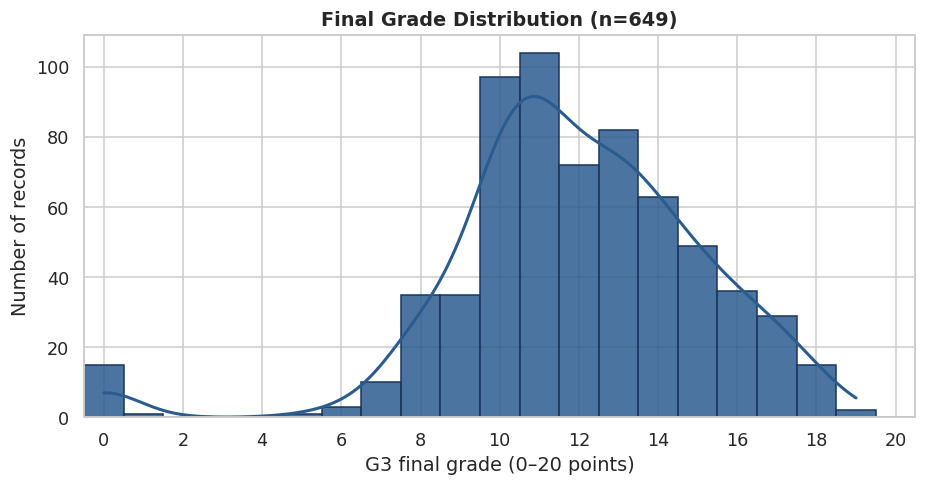

G3 mean=11.906, median=12.0, sample SD=3.231; zero grades=15.


In [11]:
fig, ax = plt.subplots(figsize=(8.6, 4.6))
sns.histplot(data=df, x='G3', bins=np.arange(-0.5, 21, 1), color='#2b5c8f', edgecolor='#1a365d', alpha=0.85, kde=True, line_kws={'linewidth': 2, 'color': '#d9534f'}, ax=ax)
ax.set(title=f'Final Grade Distribution (n={len(df)})', xlabel='G3 final grade (0–20 points)', ylabel='Number of records', xlim=(-0.5, 20.5))
ax.set_xticks(range(0, 21, 2))
save_figure(fig, '01_grade_histogram')
print(f'G3 mean={df.G3.mean():.3f}, median={df.G3.median():.1f}, sample SD={df.G3.std():.3f}; zero grades={(df.G3==0).sum()}.')

### III.1b · Seaborn box plot
The box shows Q1–Q3, the middle line is the median, whiskers extend to observations within 1.5 IQR, and remaining observations are marked as outliers. Distinct colors clearly separate the two schools (GP in steel navy, MS in coral red). School differences may reflect composition rather than school effects.

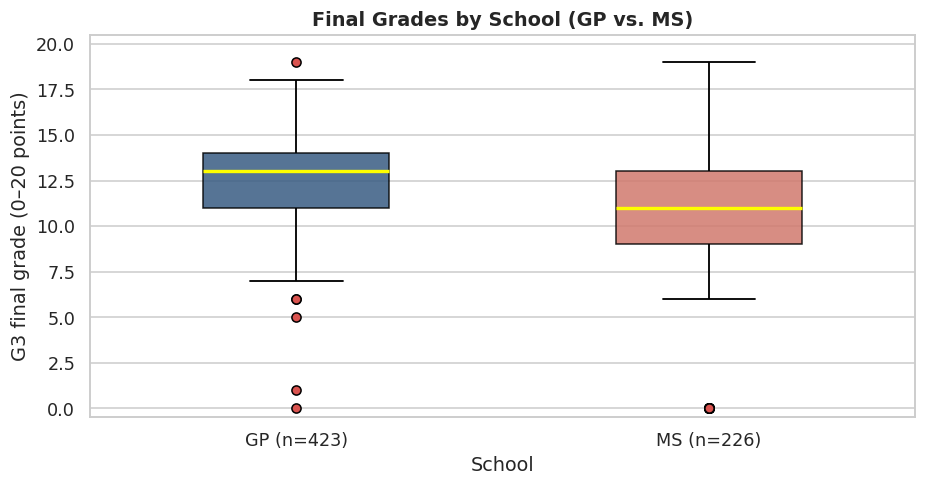

,count,mean,median,std,min,max
school,,,,,,
GP,423,12.576832,13.0,2.625636,0,19
MS,226,10.650442,11.0,3.833991,0,19


In [12]:
schools = ['GP', 'MS']
school_palette = {'GP': '#2b5c8f', 'MS': '#e26d5c'}
fig, ax = plt.subplots(figsize=(8.6, 4.6))
sns.boxplot(data=df, x='school', y='G3', order=schools, palette=school_palette, hue='school', legend=False,
            boxprops=dict(edgecolor='black', alpha=0.85),
            medianprops=dict(color='yellow', linewidth=2.2),
            whiskerprops=dict(color='black', linewidth=1.2),
            capprops=dict(color='black', linewidth=1.2),
            flierprops=dict(marker='o', markersize=6, markerfacecolor='#d9534f', markeredgecolor='black'),
            width=0.45, ax=ax)
ax.set(title='Final Grades by School (GP vs. MS)', xlabel='School', ylabel='G3 final grade (0–20 points)', ylim=(-.5, 20.5))
ax.set_xticks(range(2), [f'{s} (n={(df.school==s).sum()})' for s in schools])
save_figure(fig, '02_school_boxplot')
school_g3 = df.groupby('school', observed=True)['G3'].agg(['count', 'mean', 'median', 'std', 'min', 'max'])
display(school_g3)
save_table(school_g3, 'school_g3')

### III.2a · Comparative bar plot with Seaborn
Compare mean G3 across the original ordered study-time categories using an ascending sequential blue palette. Counts accompany each bar. The graph deliberately omits a confidence ribbon; sample means alone do not establish that increasing study time causes the observed difference.

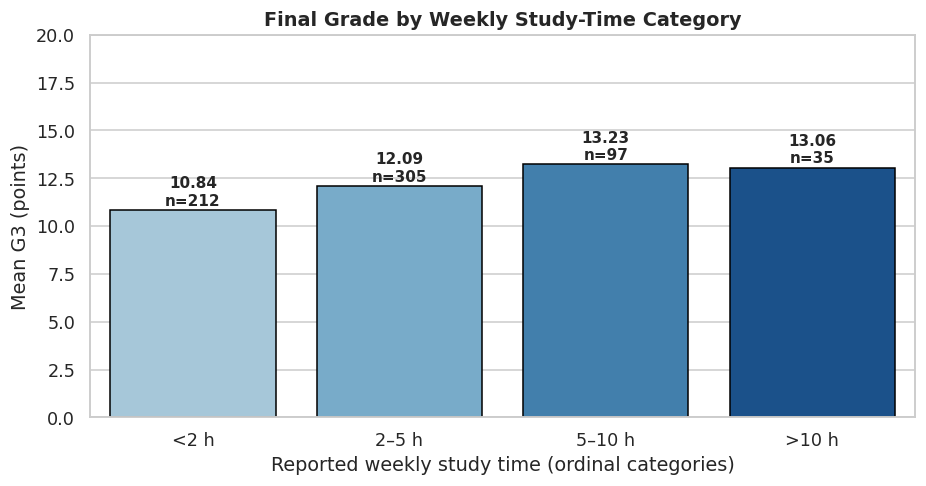

Categories are questionnaire intervals; their numeric codes are not hours.


In [13]:
study_labels = ['<2 h', '2–5 h', '5–10 h', '>10 h']
study_colors = ['#9ecae1', '#6baed6', '#3182bd', '#08519c']
fig, ax = plt.subplots(figsize=(8.6, 4.6))
sns.barplot(data=df, x='studytime', y='G3', order=[1, 2, 3, 4], palette=study_colors, hue='studytime', legend=False, errorbar=None, edgecolor='black', ax=ax)
for bar, (_, row) in zip(ax.patches, group_stats['studytime'].iterrows()):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+.25, f"{row['mean']:.2f}\nn={int(row['count'])}", ha='center', fontsize=10, fontweight='bold')
ax.set(title='Final Grade by Weekly Study-Time Category', xlabel='Reported weekly study time (ordinal categories)', ylabel='Mean G3 (points)', ylim=(0, 20))
ax.set_xticks(range(4), study_labels)
save_figure(fig, '03_studytime_bar')
print('Categories are questionnaire intervals; their numeric codes are not hours.')

### III.2b · Pie chart of the feature created in Part II
The performance bands are exhaustive, mutually exclusive, and analyst-defined. Meaningful visual colors (red for 0–9, blue for 10–14, green for 15–20) provide clear encoding of performance categories. Percentages use all 649 records.

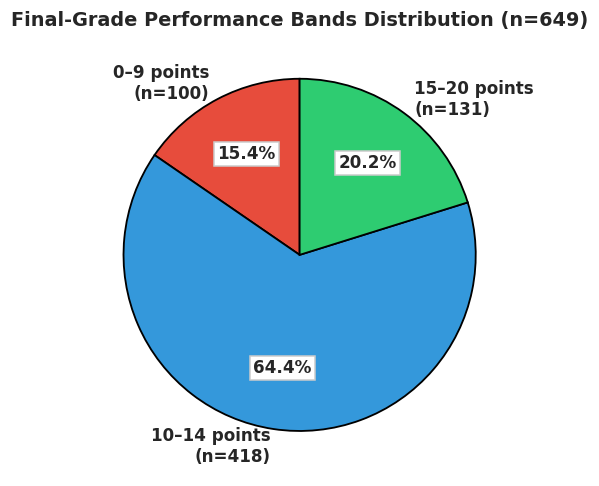

Band counts: {'0–9': 100, '10–14': 418, '15–20': 131}


In [14]:
band_counts = df['performance_band'].value_counts(sort=False).reindex(BANDS, fill_value=0)
pie_colors = ['#e74c3c', '#3498db', '#2ecc71']
fig, ax = plt.subplots(figsize=(8.6, 4.6))
wedges, _, percent_texts = ax.pie(band_counts, labels=[f'{band} points\n(n={count})' for band, count in band_counts.items()], autopct='%1.1f%%', startangle=90,
                       colors=pie_colors, wedgeprops={'edgecolor':'black', 'linewidth': 1.2}, textprops={'fontsize':11, 'fontweight': 'bold'}, pctdistance=.65)
for label in percent_texts:
    label.set_bbox({'facecolor':'white', 'edgecolor':'#cccccc', 'pad':2.0})
ax.set_title(f'Final-Grade Performance Bands Distribution (n={len(df)})', fontweight='bold')
save_figure(fig, '04_performance_pie')
print('Band counts:', band_counts.to_dict())
assert band_counts.sum() == len(df)

### III.3 · Scatter plot and descriptive regression line
Earlier-period G2 and final-period G3 are temporally related assessments. Transparency helps expose overlapping integer-coordinate observations without jittering the recorded data. The prominent red regression line highlights the positive relationship.

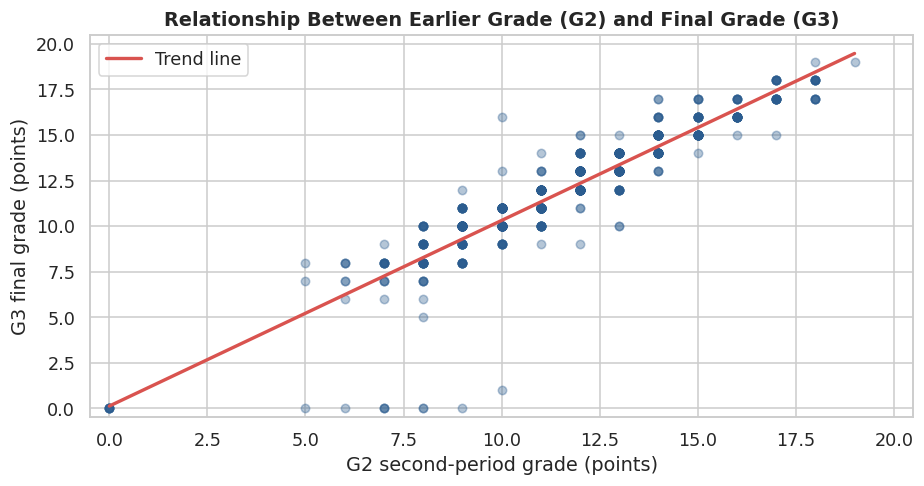

Pearson r=0.9185; Spearman rho=0.9445, n=649.


In [15]:
fig, ax = plt.subplots(figsize=(8.6, 4.6))
sns.regplot(data=df, x='G2', y='G3', ci=None, scatter_kws={'alpha':.35, 's':30, 'color':'#2b5c8f'}, line_kws={'color':'#d9534f', 'linewidth':2.2, 'label':'Trend line'}, ax=ax)
ax.set(title='Relationship Between Earlier Grade (G2) and Final Grade (G3)', xlabel='G2 second-period grade (points)', ylabel='G3 final grade (points)', xlim=(-.5,20.5), ylim=(-.5,20.5))
ax.legend(loc='upper left')
fit_line = ax.lines[0]
regression_line = {'x': fit_line.get_xdata().tolist(), 'y': fit_line.get_ydata().tolist()}
save_figure(fig, '05_g2_g3_scatter')
print(f"Pearson r={pearson.loc['G2','G3']:.4f}; Spearman rho={spearman['G2']:.4f}, n={len(df)}.")

### III.4 · Matplotlib core using ordinary Python structures
The plotting inputs below are a list and dictionary. Only Matplotlib constructs this chart. Source-record numbers identify row positions; they are not invented personal identities. Earlier-grade averages avoid including G3 in the average.

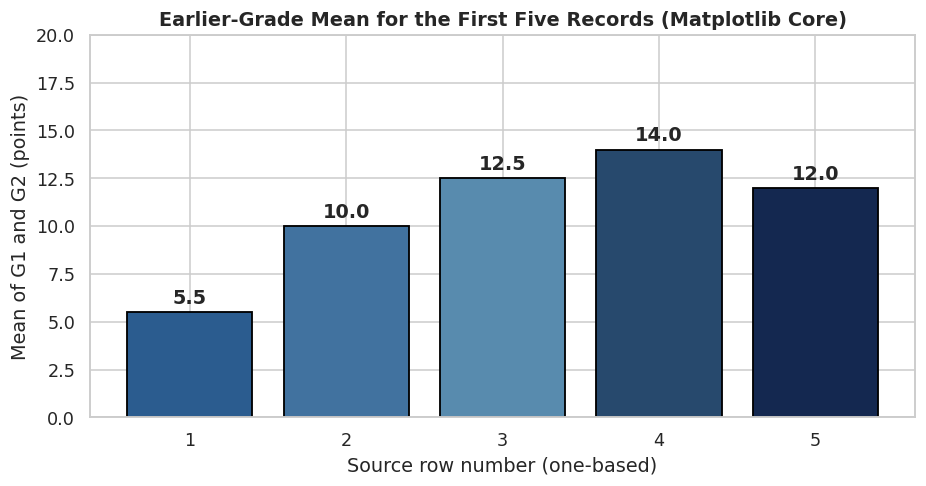

In [16]:
record_numbers = [str(index + 1) for index in df.index[:5].tolist()]
five_averages = df['prior_grade_mean'].head(5).tolist()
small_data = dict(zip(record_numbers, five_averages))
assert isinstance(five_averages, list) and isinstance(small_data, dict)
fig, ax = plt.subplots(figsize=(8.6, 4.6))
bar_colors = ['#2b5c8f', '#41729f', '#588bae', '#27496d', '#142850']
bars = ax.bar(list(small_data.keys()), list(small_data.values()), color=bar_colors, edgecolor='black', linewidth=1.2)
ax.bar_label(bars, fmt='%.1f', padding=3, fontweight='bold')
ax.set(title='Earlier-Grade Mean for the First Five Records (Matplotlib Core)', xlabel='Source row number (one-based)', ylabel='Mean of G1 and G2 (points)', ylim=(0,20))
save_figure(fig, '06_matplotlib_core')

## PART IV — Synthesis and conclusion
### IV.1 · A reusable comprehensive report
The named function takes a DataFrame, displays a summary, and returns a dictionary. It contains total records, missing counts, grade statistics and performance-band counts/percentages. Its input is explicit; it does not silently read global data or access the network.

In [17]:
summary = comprehensive_report(df)
assert summary['total_records'] == 649
assert sum(item['count'] for item in summary['performance_distribution'].values()) == 649
assert np.isclose(sum(item['percent'] for item in summary['performance_distribution'].values()), 100)

{
  "total_records": 649,
  "total_columns": 37,
  "missing_by_column": {
    "school": 0,
    "sex": 0,
    "age": 0,
    "address": 0,
    "famsize": 0,
    "Pstatus": 0,
    "Medu": 0,
    "Fedu": 0,
    "Mjob": 0,
    "Fjob": 0,
    "reason": 0,
    "guardian": 0,
    "traveltime": 0,
    "studytime": 0,
    "failures": 0,
    "schoolsup": 0,
    "famsup": 0,
    "paid": 0,
    "activities": 0,
    "nursery": 0,
    "higher": 0,
    "internet": 0,
    "romantic": 0,
    "famrel": 0,
    "freetime": 0,
    "goout": 0,
    "Dalc": 0,
    "Walc": 0,
    "health": 0,
    "absences": 0,
    "G1": 0,
    "G2": 0,
    "prior_grade_mean": 0,
    "G3": 0,
    "grade_progress": 0,
    "performance_band": 0,
    "G3_minmax_school": 0
  },
  "grade_statistics": {
    "G1": {
      "count": 649.0,
      "mean": 11.3990755008,
      "std": 2.7452651284,
      "min": 0.0,
      "median": 11.0,
      "max": 19.0
    },
    "G2": {
      "count": 649.0,
      "mean": 11.5701078582,
      "std": 2.9

### IV.2a · Highest and lowest ten records with all columns
Sort by G3, preserving original source order for ties, then take exactly ten. Equal-grade records outside the ten are substantively tied. All original columns and engineered columns are visible in the HTML output and retained in the CSV exports; horizontal scrolling is preferable to hiding evidence.

In [18]:
top_ten = df.sort_values('G3', ascending=False, kind='stable').head(10)
bottom_ten = df.sort_values('G3', ascending=True, kind='stable').head(10)
print('TOP TEN — all columns, source index is zero-based')
display(top_ten)
print('BOTTOM TEN — all columns, source index is zero-based')
display(bottom_ten)
assert len(top_ten) == len(bottom_ten) == 10
assert top_ten.columns.equals(df.columns) and bottom_ten.columns.equals(df.columns)
assert top_ten['G3'].is_monotonic_decreasing and bottom_ten['G3'].is_monotonic_increasing
for frame in [top_ten, bottom_ten]:
    for grade, rows in frame.groupby('G3', sort=False):
        assert rows.index.is_monotonic_increasing
save_table(top_ten.rename_axis('source_index'), 'top_10_all_columns')
save_table(bottom_ten.rename_axis('source_index'), 'bottom_10_all_columns')

TOP TEN — all columns, source index is zero-based


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,prior_grade_mean,G3,grade_progress,performance_band,G3_minmax_school
338,GP,F,17,R,LE3,T,3,1,services,other,reputation,mother,2,4,0,no,yes,no,no,yes,yes,no,no,3,1,2,1,1,3,0,18,19,18.5,19,1,15–20,1.000000
636,MS,M,18,U,GT3,T,4,4,teacher,teacher,home,father,1,2,0,no,no,no,yes,no,yes,yes,no,3,2,4,1,4,2,4,17,18,17.5,19,1,15–20,1.000000
113,GP,M,15,U,LE3,T,4,2,teacher,other,course,mother,1,1,0,no,no,no,no,yes,yes,yes,no,3,5,2,1,1,3,10,18,17,17.5,18,-1,15–20,0.947368
181,GP,F,16,U,GT3,T,4,2,health,services,home,father,1,2,0,no,no,no,no,yes,yes,yes,yes,4,2,3,1,1,3,0,17,17,17.0,18,0,15–20,0.947368
185,GP,M,16,U,GT3,T,1,0,other,other,reputation,mother,2,2,0,no,yes,no,yes,yes,yes,yes,yes,4,3,2,1,1,3,0,16,17,16.5,18,1,15–20,0.947368
314,GP,M,17,R,GT3,T,1,2,at_home,at_home,home,mother,1,2,0,no,yes,no,yes,no,yes,no,yes,3,5,2,2,2,1,2,16,17,16.5,18,1,15–20,0.947368
327,GP,F,18,R,LE3,T,1,1,at_home,other,reputation,mother,2,4,0,no,yes,no,yes,yes,yes,no,no,5,2,2,1,1,3,2,17,17,17.0,18,0,15–20,0.947368
332,GP,F,18,U,GT3,T,2,2,at_home,at_home,other,mother,1,3,0,no,yes,no,no,yes,yes,yes,no,4,3,3,1,2,2,0,18,18,18.0,18,0,15–20,0.947368
337,GP,F,17,U,GT3,T,4,3,health,services,reputation,mother,1,3,0,no,yes,no,no,yes,yes,yes,no,4,2,2,1,2,3,0,17,18,17.5,18,1,15–20,0.947368
349,GP,F,17,U,GT3,T,3,2,health,health,reputation,father,1,4,0,no,yes,no,yes,no,yes,yes,no,5,2,2,1,2,5,0,18,18,18.0,18,0,15–20,0.947368


BOTTOM TEN — all columns, source index is zero-based


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,prior_grade_mean,G3,grade_progress,performance_band,G3_minmax_school
163,GP,M,18,U,LE3,T,1,1,other,other,course,mother,1,1,2,no,no,no,no,yes,no,yes,yes,2,3,5,2,5,4,0,11,9,10.0,0,-2,0–9,0.0
440,MS,M,16,U,GT3,T,1,1,at_home,services,home,mother,2,2,0,no,yes,no,yes,yes,yes,no,yes,5,4,5,4,5,3,0,7,0,3.5,0,-7,0–9,0.0
519,MS,M,16,R,GT3,T,2,1,other,services,reputation,mother,2,2,0,no,no,no,yes,yes,yes,yes,no,5,2,1,1,1,2,0,8,7,7.5,0,-1,0–9,0.0
563,MS,M,17,U,GT3,T,2,2,other,other,course,mother,1,1,1,no,no,no,yes,yes,yes,no,yes,1,2,1,2,3,5,0,7,0,3.5,0,-7,0–9,0.0
567,MS,M,18,R,GT3,T,3,2,services,other,course,mother,1,1,1,no,no,no,no,yes,no,yes,no,2,3,1,2,2,5,0,4,0,2.0,0,-4,0–9,0.0
583,MS,F,18,R,GT3,T,2,2,other,other,other,mother,2,1,1,no,no,no,no,yes,no,yes,yes,5,5,5,1,1,3,0,8,6,7.0,0,-2,0–9,0.0
586,MS,F,17,U,GT3,T,4,2,teacher,services,home,mother,1,2,0,yes,yes,no,yes,yes,yes,yes,no,5,5,5,1,3,5,0,8,8,8.0,0,0,0–9,0.0
597,MS,F,18,R,GT3,T,2,2,at_home,other,course,mother,3,2,1,no,no,no,yes,yes,yes,no,yes,4,3,3,1,1,4,0,9,0,4.5,0,-9,0–9,0.0
603,MS,F,18,R,LE3,A,4,2,teacher,other,reputation,mother,1,2,0,no,no,no,yes,yes,yes,yes,yes,5,3,1,1,1,5,0,5,0,2.5,0,-5,0–9,0.0
605,MS,F,19,U,GT3,T,1,1,at_home,services,other,father,2,1,1,no,no,no,no,yes,no,no,no,5,5,5,2,3,2,0,5,0,2.5,0,-5,0–9,0.0


### IV.2b · Evidence-based synthesis
The next cell reports the strongest observed association among the examined original numerical/ordinal contextual factors, separately from prior grades. It must be read alongside group sizes, the figures and the sensitivity analysis. No multivariate adjustment or experiment was performed, so these associations do not identify causes or interventions.

In [19]:
best_prior = prior_rankings.iloc[0]
best_context = context_rankings.iloc[0]
print(f"Strongest prior-grade association: {best_prior.variable}, rho={best_prior.spearman_rho:.4f}.")
print(f"Strongest contextual numerical/ordinal association examined: {best_context.variable}, rho={best_context.spearman_rho:.4f}.")
print(f"Final grade: mean={df.G3.mean():.3f}, median={df.G3.median():.1f}, sample SD={df.G3.std():.3f}.")
print('Group summaries are descriptive; categorical mean differences are not ranked against correlation coefficients.')
print('Limitations: two schools in Portugal, observational questionnaires, ordinal coding, tied scores, possible confounding, and one MCAR simulation.')

Strongest prior-grade association: G2, rho=0.9445.
Strongest contextual numerical/ordinal association examined: failures, rho=-0.4484.
Final grade: mean=11.906, median=12.0, sample SD=3.231.
Group summaries are descriptive; categorical mean differences are not ranked against correlation coefficients.
Limitations: two schools in Portugal, observational questionnaires, ordinal coding, tied scores, possible confounding, and one MCAR simulation.


### IV.3 · Export authoritative artifacts and verification evidence
All report and slide numbers are read from these exports. Document builders must not run a second statistical pipeline. The manifest records source checksum, seed, dataset variants, environment and artifact hashes. Small tolerances apply only to floating-point comparisons, not counts or labels.

In [20]:
box_data = {}
for school in schools:
    stats = boxplot_stats(df.loc[df.school.eq(school), 'G3'].to_numpy(), whis=1.5)[0]
    box_data[school] = {name: (value.tolist() if isinstance(value, np.ndarray) else float(value)) for name, value in stats.items() if name != 'label'}

summary.update({
    'dataset': {'subject':'Portuguese language', 'rows':len(raw), 'columns':raw.shape[1], 'numeric_columns':NUMERIC_COLUMNS,
                'duplicate_attribute_rows':int(raw.duplicated().sum()), 'school_counts':raw.school.value_counts().to_dict(),
                'observed_G3_range':[int(raw.G3.min()),int(raw.G3.max())], 'observed_absences_range':[int(raw.absences.min()),int(raw.absences.max())]},
    'missing_simulation': {'column':'absences', 'seed':42, 'masked_count':len(masked_indices), 'percent':100*len(masked_indices)/len(raw), 'observed_mean':float(observed_mean)},
    'missing_comparison': json.loads(missing_comparison.to_json(orient='records')),
    'sensitivity': json.loads(sensitivity.to_json(orient='records')),
    'filter': {'count':len(filtered), 'percent':100*len(filtered)/len(df)},
    'rankings': json.loads(rankings.to_json(orient='records')),
    'school_g3': json.loads(school_g3.reset_index().to_json(orient='records')),
    'group_stats': {name:json.loads(table.reset_index().to_json(orient='records')) for name,table in group_stats.items()},
    'charts': {'histogram':df.G3.value_counts().reindex(range(21),fill_value=0).tolist(), 'box':box_data,
               'scatter':{'x':df.G2.tolist(),'y':df.G3.tolist(),'fit':regression_line},
               'core':{'records':record_numbers,'values':five_averages}},
    'top_ten': json.loads(top_ten.rename_axis('source_index').reset_index().to_json(orient='records')),
    'bottom_ten': json.loads(bottom_ten.rename_axis('source_index').reset_index().to_json(orient='records')),
    'pearson_G2_G3':float(pearson.loc['G2','G3']),
})
(ROOT/'results/summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2,allow_nan=False)+'\n',encoding='utf-8')
artifacts = sorted([*TABLES.glob('*.csv'), *FIGURES.glob('*.png'), *FIGURES.glob('*.svg'), * (ROOT/'data/processed').glob('*.csv'), ROOT/'results/summary.json'])
manifest = {'raw_file':'data/raw/student-por.csv','raw_sha256':raw_hash,'primary_variant':'validated original complete measurements',
            'simulation_seed':42,'masked_source_indices':masked_indices.tolist(),
            'versions':{name:importlib.metadata.version(name) for name in ['numpy','pandas','matplotlib','seaborn','scipy','nbformat','nbclient','ipykernel']},
            'artifacts':{str(path.relative_to(ROOT)):hashlib.sha256(path.read_bytes()).hexdigest() for path in artifacts}}
(ROOT/'results/manifest.json').write_text(json.dumps(manifest,indent=2)+'\n')
print('All assignment assertions passed; authoritative artifacts exported.')
print('Tables:', len(list(TABLES.glob('*.csv'))), 'figures:', len(list(FIGURES.glob('*.png'))))

All assignment assertions passed; authoritative artifacts exported.
Tables: 14 figures: 6


## References and reproducibility notes
- Cortez, P. (2008). *Student Performance* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5TG7T. CC BY 4.0.
- Original data documentation: `references/student.txt` and `references/dataset_source.json`.
- Pandas documentation: https://pandas.pydata.org/docs/ (indexing, missing data, groupby and correlation).
- Seaborn documentation: https://seaborn.pydata.org/ (histplot, boxplot, barplot and regplot).
- Matplotlib documentation: https://matplotlib.org/stable/ (core axes, bar and pie charts).

No signatures, personal identities in the dataset, contribution percentages or causal results are invented. The accompanying report and presentation interpret the outputs of this notebook, not independent recalculations.